In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
df = pd.read_csv('tshirt_sizes.csv')
df.head()

,height_cm,weight_kg,size
0,159.8,62.8,S
1,164.6,50.5,S
2,179.2,65.7,L
3,156.8,54.3,S
4,173.6,62.3,M


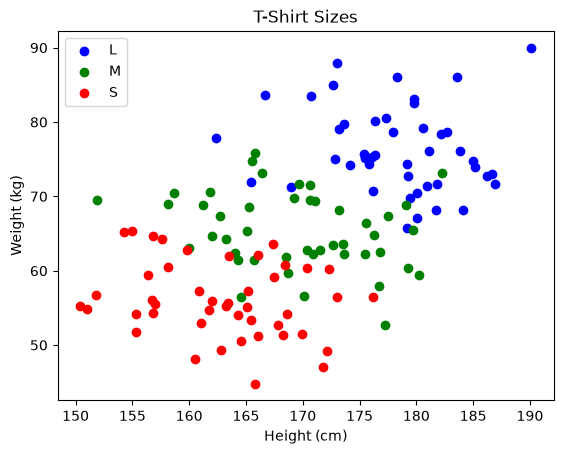

In [3]:
colors = {'S':'red', 'M':'green', 'L':'blue', 'XL':'orange'}

for name, group in df.groupby('size'):
    plt.scatter(group.height_cm, group.weight_kg, marker='o', color=colors[name], label=name)

plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.title('T-Shirt Sizes')
plt.legend()
plt.show()


In [4]:
X  = df[['height_cm', 'weight_kg']]
y = df['size']

In [5]:
print("Shape of X:", X.shape)
print("Unique values in y:", y.unique())

Shape of X: (135, 2)
Unique values in y: <ArrowStringArray>
['S', 'L', 'M']
Length: 3, dtype: str


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

c:\Users\SAKSHI\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [7]:
y_pred = model.predict(X_test)

In [8]:
compare = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})

compare.head(10)

,Actual,Predicted
98,M,M
67,S,S
105,M,M
19,S,M
42,M,M
62,S,S
12,S,S
110,M,M
125,S,S
128,S,M


In [9]:
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           L       0.88      1.00      0.93         7
           M       0.82      0.90      0.86        10
           S       1.00      0.80      0.89        10

    accuracy                           0.89        27
   macro avg       0.90      0.90      0.89        27
weighted avg       0.90      0.89      0.89        27



In [10]:
accuracy = model.score(X_test,y_test)
print(f"Model Accuracy: {accuracy:.2f}")

Model Accuracy: 0.89


In [11]:
sizes = ['S', 'M', 'L']

cm = confusion_matrix(y_test, y_pred, labels=sizes)
cm

array([[8, 2, 0],
       [0, 9, 1],
       [0, 0, 7]])

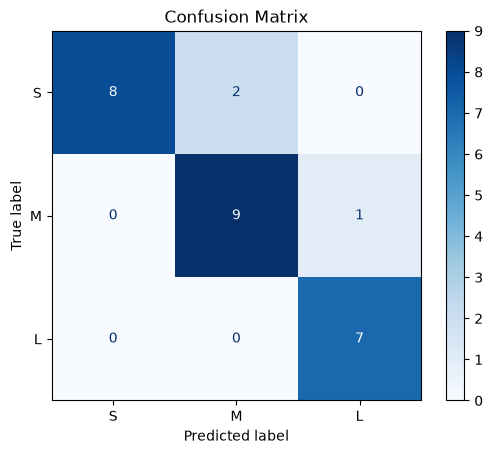

In [12]:
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sizes)
display_cm.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

In [13]:
new_customer = pd.DataFrame([{'height_cm': 170, 'weight_kg': 70}])
print("Predicting size for new data:", model.predict(new_customer)[0])

Predicting size for new data: M
